# Market Analysis and Stock Segmentation Using RFM
**6BUIS017W | CRM & CM With Business Intelligence | CWK1**

Study period: 1 January 2021 to 1 January 2025 (end exclusive). Benchmark: S&P 500 (`^GSPC`).

## Setup

In [50]:
# Install the Python libraries required for data retrieval, analysis and plotting.
%pip -q install yfinance lxml html5lib beautifulsoup4

In [51]:
# Code for the current analysis step.
from __future__ import annotations
import json
import hashlib
import sys
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
from IPython.display import display
import matplotlib.pyplot as plt
import scipy
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
import sklearn
import yfinance as yf
ROOT = Path.cwd() / 'cwk1_analysis'
DATA = ROOT / 'data'
OUT = ROOT / 'outputs'

for p in [DATA, OUT]:
    p.mkdir(parents=True, exist_ok=True)
START = '2021-01-01'
END = '2025-01-01'
SEED = 42
SOURCE = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'


plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'axes.axisbelow': True, 'grid.alpha': 0.2, 'axes.spines.top': False, 'axes.spines.right': False})

## Task 1: Data Preparation and Feature Engineering

### 1.1 Ticker selection and data acquisition

yfinance provides daily Close, Adj Close, Volume and corporate action fields. The current constituent list introduces survivorship bias when used for the historical study.

In [52]:
# Code for the current analysis step.
def write_json(path, x):
    path.write_text(json.dumps(x, indent=2, default=str), encoding="utf-8")

def sha(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def acquisition():
    constituent_file = DATA / "constituents.csv"
    if constituent_file.exists():
        cons = pd.read_csv(constituent_file)
        if "retrieved_utc" not in cons.columns:
            cons["retrieved_utc"] = "Previously cached; original retrieval timestamp unavailable"
    else:
        cons = pd.read_html(
            SOURCE, storage_options={"User-Agent": "Mozilla/5.0"}
        )[0]
        needed = ["Symbol", "Security", "GICS Sector", "GICS Sub-Industry"]
        if not all(c in cons.columns for c in needed):
            raise RuntimeError("The S&P 500 constituent page has changed; inspect its table before continuing.")
        cons = cons[needed].copy()
        cons["retrieved_utc"] = datetime.now(timezone.utc).isoformat()
        cons.to_csv(constituent_file, index=False)

    cons["YahooTicker"] = cons["Symbol"].astype(str).str.replace(".", "-", regex=False)
    tickers = cons["YahooTicker"].drop_duplicates().tolist()
    all_names = tickers + ["^GSPC"]
    failed = []

    # Individual files make partial downloads reusable if a request is interrupted.
    for number, ticker in enumerate(all_names, start=1):
        path = DATA / f"{ticker.replace('^', 'INDEX_')}.csv"
        if path.exists() and path.stat().st_size > 100:
            continue
        downloaded = False
        for attempt in range(1, 4):
            try:
                d = yf.download(
                    ticker, start=START, end=END, interval="1d",
                    auto_adjust=False, actions=True, progress=False,
                    threads=False, timeout=30, multi_level_index=False
                )
                if d is not None and not d.empty:
                    if isinstance(d.columns, pd.MultiIndex):
                        d.columns = d.columns.get_level_values(0)
                    d.index = pd.to_datetime(d.index)
                    if d.index.tz is not None:
                        d.index = d.index.tz_localize(None)
                    d.index = d.index.normalize()
                    d.index.name = "Date"
                    d.to_csv(path)
                    downloaded = True
                    break
                print(f"No data returned for {ticker} (attempt {attempt})")
            except Exception as exc:
                print(f"Download issue for {ticker}, attempt {attempt}: {str(exc)[:140]}")
            time.sleep(1.5 * attempt)
        if not downloaded:
            failed.append(ticker)
        if number % 25 == 0:
            print(f"Checked {number}/{len(all_names)} tickers; failed so far: {len(failed)}")

    write_json(OUT / "download_failures.json", {"failed_tickers": failed})
    if not (DATA / "INDEX_GSPC.csv").exists():
        raise RuntimeError("S&P 500 benchmark download failed. Re-run this cell to retry.")
    return cons

def get_daily(ticker):
    path = DATA / f"{ticker.replace('^', 'INDEX_')}.csv"
    if not path.exists():
        return None
    x = pd.read_csv(path, index_col="Date", parse_dates=True)
    x.index = pd.to_datetime(x.index)
    if x.index.tz is not None:
        x.index = x.index.tz_localize(None)
    x.index = x.index.normalize()
    x = x[~x.index.duplicated(keep="last")].sort_index()
    return x

In [53]:
# Define reusable helpers and download/cache the S&P 500 constituents and price histories.
import time
constituents = acquisition()
display(constituents.head())
print(f"Constituent records: {len(constituents):,}")
retrieval_value = constituents["retrieved_utc"].iloc[0]
print("Constituent retrieval:", retrieval_value)

versions = {
    "python": sys.version.split()[0], "pandas": pd.__version__,
    "numpy": np.__version__, "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
    "yfinance": yf.__version__
}
display(pd.Series(versions, name="Version").to_frame())

write_json(OUT / "provenance.json", {
    "source": SOURCE,
    "constituent_retrieved_utc": retrieval_value,
    "study_window_start_inclusive_end_exclusive": [START, END],
    "benchmark": "^GSPC",
    "versions": versions,
    "snapshot_sha256": {p.name: sha(p) for p in DATA.glob("*.csv")}
})

ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


No data returned for FDXF (attempt 1)


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


No data returned for FDXF (attempt 2)


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


No data returned for FDXF (attempt 3)


... (23 outputs left out)

No data returned for VYLR (attempt 3)


,Symbol,Security,GICS Sector,GICS Sub-Industry,retrieved_utc,YahooTicker
0,MMM,3M,Industrials,Industrial Conglomerates,2026-11-23T05:57:38.171144+00:00,MMM
1,AOS,A. O. Smith,Industrials,Building Products,2026-11-23T05:57:38.171144+00:00,AOS
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,2026-11-23T05:57:38.171144+00:00,ABT
3,ABBV,AbbVie,Health Care,Biotechnology,2026-11-23T05:57:38.171144+00:00,ABBV
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,2026-11-23T05:57:38.171144+00:00,ACN


Constituent records: 503
Constituent retrieval: 2026-11-23T05:57:38.171144+00:00


,Version
python,3.13.18
pandas,2.2.3
numpy,2.4.6
scipy,1.16.3
scikit-learn,1.6.1
matplotlib,3.10.0
yfinance,0.2.66


### 1.2 Data validation and alignment



In [54]:
# Code for the current analysis step.
benchmark = get_daily("^GSPC")
if benchmark is None or benchmark.empty:
    raise RuntimeError("Benchmark data is missing. Re-run acquisition.")
benchmark = benchmark.loc[(benchmark.index >= START) & (benchmark.index < END)].copy()

assert not benchmark.index.duplicated().any(), "Duplicate benchmark dates"
required_benchmark = ["Adj Close"]
assert set(required_benchmark).issubset(benchmark.columns)
benchmark = benchmark.replace([np.inf, -np.inf], np.nan)
assert benchmark["Adj Close"].notna().all() and benchmark["Adj Close"].gt(0).all()

observation_date = benchmark.index.max()
print("Benchmark first date:", benchmark.index.min().date())
print("Benchmark final observation date:", observation_date.date())
print("Benchmark trading sessions:", len(benchmark))

# Friday labels cover complete weekly intervals in the requested study window.
week_labels = pd.date_range("2021-01-08", "2024-12-27", freq="W-FRI")

histories = {}
validation = []
for row in constituents.itertuples(index=False):
    ticker = row.YahooTicker
    daily = get_daily(ticker)
    reasons = []
    split_days = dividend_days = np.nan
    missing_sessions = np.nan
    required_fields = ["Close", "Adj Close", "Volume", "Stock Splits", "Dividends"]

    if daily is None:
        reasons.append("Unavailable data")
    else:
        daily = daily.loc[(daily.index >= START) & (daily.index < END)].copy()
        missing_sessions = len(benchmark.index.difference(daily.index))
        if daily.index.duplicated().any():
            reasons.append("Duplicate dates")
        if missing_sessions or not daily.index.isin(benchmark.index).all():
            reasons.append("Incomplete or unequal trading history")
        if not set(required_fields).issubset(daily.columns):
            reasons.append("Missing required price, volume or corporate-action fields")
        else:
            numeric = daily[required_fields].apply(pd.to_numeric, errors="coerce")
            if not np.isfinite(numeric.to_numpy(dtype=float)).all():
                reasons.append("Missing or non-finite required values")
            if numeric[["Close", "Adj Close"]].le(0).any().any():
                reasons.append("Non-positive prices")
            if numeric["Volume"].le(0).any():
                reasons.append("Missing or non-positive volume")
            split_days = int(numeric["Stock Splits"].ne(0).sum())
            dividend_days = int(numeric["Dividends"].ne(0).sum())
            if numeric["Stock Splits"].lt(0).any() or numeric["Dividends"].lt(0).any():
                reasons.append("Invalid corporate-action values")
            daily[required_fields] = numeric

    if not reasons:
        histories[ticker] = daily
    validation.append({
        "Ticker": ticker, "MissingSessions": missing_sessions,
        "SplitDays": split_days, "DividendDays": dividend_days,
        "Status": "Valid" if not reasons else "Excluded",
        "Reason": "; ".join(reasons)
    })

validation = pd.DataFrame(validation).set_index("Ticker")
print("Valid full-period share histories:", len(histories))
print("Excluded shares:", int((validation["Status"] == "Excluded").sum()))
display(validation["Status"].value_counts().to_frame("Share_Count"))
if not histories:
    raise RuntimeError("No valid full-period share histories remain. Check data download and validation log.")

Benchmark first date: 2021-01-04
Benchmark final observation date: 2024-12-31
Benchmark trading sessions: 1005
Valid full-period share histories: 486
Excluded shares: 17


,Share_Count
Status,
Valid,486
Excluded,17


### 1.3 Weekly return and weekly beta

#### 1.3.1 Mean weekly return

In [55]:
# Code for the current analysis step.
def weekly_returns(daily):
    prices = daily['Adj Close'].resample('W-FRI').last().reindex(week_labels)
    return prices.pct_change(fill_method=None)

benchmark_returns = weekly_returns(benchmark).dropna()
share_returns = pd.DataFrame({ticker: weekly_returns(daily)
                              for ticker, daily in histories.items()})
share_returns = share_returns.reindex(benchmark_returns.index)
assert share_returns.notna().all().all(), 'Weekly alignment failure'
features = constituents.set_index('YahooTicker').loc[list(histories), ['Security', 'GICS Sector']].copy()
features.index.name = 'Ticker'
features.rename(columns={'GICS Sector': 'Sector'}, inplace=True)
features['MeanWeeklyReturn'] = share_returns.mean()
features['WeeklyN'] = share_returns.count()
display(features[['MeanWeeklyReturn', 'WeeklyN']])

,MeanWeeklyReturn,WeeklyN
Ticker,,
MMM,0.001142,207
AOS,0.001991,207
ABT,0.000971,207
ABBV,0.003749,207
ACN,0.002376,207
...,...,...
XYL,0.001358,207
YUM,0.001807,207
ZBRA,0.001181,207


#### 1.3.2 Weekly beta

In [56]:
# Code for the current analysis step.
market_variance = benchmark_returns.var()
assert market_variance > 0
features['WeeklyBeta'] = share_returns.apply(lambda returns: returns.cov(benchmark_returns) / market_variance)
display(features[['WeeklyBeta', 'WeeklyN']])

,WeeklyBeta,WeeklyN
Ticker,,
MMM,0.869079,207
AOS,1.042804,207
ABT,0.583543,207
ABBV,0.425366,207
ACN,1.143300,207
...,...,...
XYL,1.138380,207
YUM,0.631435,207
ZBRA,1.618418,207


### 1.4 Adapted RFM Calculations

#### 1.4.1 Recency

In [57]:
# Code for the current analysis step.
events = {}
for ticker, daily in histories.items():
    prior_mean = daily['Volume'].shift(1).rolling(20, min_periods=20).mean()
    event = daily['Volume'].gt(2 * prior_mean) & prior_mean.notna()
    assert prior_mean.tail(60).notna().all()
    events[ticker] = pd.DataFrame({'Close': daily['Close'], 'Volume': daily['Volume'],
                                   'Prior20Mean': prior_mean, 'Threshold': 2 * prior_mean,
                                   'Qualifies': event})

latest_events = pd.Series({ticker: evidence.index[evidence['Qualifies']].max()
                           for ticker, evidence in events.items()})
features['ObservationDate'] = observation_date
features['LatestEvent'] = latest_events
features['R'] = (observation_date - latest_events).dt.days
no_event = features.index[features['R'].isna()]
validation.loc[no_event, 'Status'] = 'Excluded'
validation.loc[no_event, 'Reason'] = 'No qualifying high-volume event; Recency missing'
display(features[['ObservationDate', 'LatestEvent', 'R']])

,ObservationDate,LatestEvent,R
Ticker,,,
MMM,2024-12-31,2024-12-20,11
AOS,2024-12-31,2024-12-20,11
ABT,2024-12-31,2024-12-20,11
ABBV,2024-12-31,2024-12-20,11
ACN,2024-12-31,2024-12-20,11
...,...,...,...
XYL,2024-12-31,2024-11-25,36
YUM,2024-12-31,2024-11-05,56
ZBRA,2024-12-31,2024-12-20,11


#### 1.4.2 Frequency

In [58]:
# Code for the current analysis step.
features['F'] = pd.Series({ticker: int(evidence['Qualifies'].tail(60).sum())
                           for ticker, evidence in events.items()})
display(features[['F']])

,F
Ticker,
MMM,4
AOS,2
ABT,1
ABBV,3
ACN,2
...,...
XYL,3
YUM,1
ZBRA,4


#### 1.4.3 Monetary

In [59]:
# Code for the current analysis step.
features['M'] = pd.Series({ticker: (evidence['Close'] * evidence['Volume']).tail(60).sum()
                           for ticker, evidence in events.items()})
display(features[['M']])

,M
Ticker,
MMM,2.599146e+10
AOS,4.748980e+09
ABT,3.523027e+10
ABBV,6.837054e+10
ACN,5.199430e+10
...,...
XYL,1.017679e+10
YUM,1.339492e+10
ZBRA,8.326927e+09


### 1.5 Metric interpretation and supporting evidence

Mean weekly return measures historical average return; beta measures benchmark sensitivity. Recency measures elapsed calendar days since unusual activity, Frequency counts qualifying days, and Monetary approximates traded value in USD. These measures do not establish future returns, company value or portfolio diversification.

In [60]:
# Code for the current analysis step.
validation.loc[features.index.difference(no_event), 'Status'] = 'Included'
validation.to_csv(OUT / 'inclusion_exclusion_log.csv')
display(validation)
features = features.dropna(subset=['R']).reset_index()
assert len(features) >= 9, 'Insufficient common shares for cluster counts 2 to 8'
features['R'] = features['R'].astype(int)
metrics = ['MeanWeeklyReturn', 'WeeklyBeta', 'R', 'F', 'M']
display(features[metrics].describe())

example = features.iloc[0]
evidence = events[example.Ticker]
worked = evidence.tail(60).copy()
worked['TradedValue'] = worked['Close'] * worked['Volume']
display(example[['Ticker', 'ObservationDate', 'LatestEvent', 'R', 'F', 'M']].to_frame('Worked example'))
display(evidence.loc[[example.LatestEvent]])
display(worked)
assert worked['Qualifies'].sum() == example.F
assert np.isclose(worked['TradedValue'].sum(), example.M)
assert (observation_date - example.LatestEvent).days == example.R
assert np.isclose(evidence.loc[example.LatestEvent, 'Prior20Mean'],
                  evidence.loc[:example.LatestEvent, 'Volume'].iloc[-21:-1].mean())
provenance = json.loads((OUT / 'provenance.json').read_text())
provenance['observation_date'] = str(observation_date.date())
write_json(OUT / 'provenance.json', provenance)

# Task 1 evidence: descriptive summaries and a fully reproducible feature table.
feature_summary = features[metrics].describe().T
feature_summary.to_csv(OUT / "task1_feature_summary.csv")
features.to_csv(OUT / "task1_feature_table.csv", index=False)
print("Task 1 feature summary:")
display(feature_summary)
print("Included share count:", len(features))
print("Observation date:", observation_date.date())


,MissingSessions,SplitDays,DividendDays,Status,Reason
Ticker,,,,,
MMM,0.0,1.0,16.0,Included,
AOS,0.0,0.0,16.0,Included,
ABT,0.0,0.0,16.0,Included,
ABBV,0.0,0.0,16.0,Included,
ACN,0.0,0.0,16.0,Included,
...,...,...,...,...,...
XYL,0.0,0.0,16.0,Included,
YUM,0.0,0.0,16.0,Included,
ZBRA,0.0,0.0,0.0,Included,


,MeanWeeklyReturn,WeeklyBeta,R,F,M
count,486.000000,486.000000,486.000000,486.000000,4.860000e+02
mean,0.002857,0.973695,20.407407,2.989712,3.940419e+10
std,0.002652,0.407339,21.342438,1.330800,1.291388e+11
min,-0.004468,0.055452,4.000000,0.000000,1.297483e+09
25%,0.001182,0.666599,11.000000,2.000000,1.019517e+10
50%,0.002619,0.950610,11.000000,3.000000,1.668382e+10
75%,0.004207,1.179538,14.750000,4.000000,3.227689e+10
max,0.017772,3.778560,222.000000,8.000000,1.847697e+12


,Worked example
Ticker,MMM
ObservationDate,2024-12-31 00:00:00
LatestEvent,2024-12-20 00:00:00
R,11
F,4
M,25991458733.34198


,Close,Volume,Prior20Mean,Threshold,Qualifies
Date,,,,,
2024-12-20,129.279999,8351300,3027540.0,6055080.0,True


,Close,Volume,Prior20Mean,Threshold,Qualifies,TradedValue
Date,,,,,,
2024-10-07,134.850006,2254200,3568210.0,7136420.0,False,3.039789e+08
2024-10-08,134.690002,2882100,3500105.0,7000210.0,False,3.881901e+08
2024-10-09,135.009995,2671400,3507585.0,7015170.0,False,3.606657e+08
2024-10-10,133.460007,3060100,3476965.0,6953930.0,False,4.084010e+08
2024-10-11,134.750000,3103600,3431030.0,6862060.0,False,4.182101e+08
2024-10-14,135.759995,2207900,3452705.0,6905410.0,False,2.997445e+08
2024-10-15,135.729996,2465800,3409635.0,6819270.0,False,3.346830e+08
2024-10-16,136.350006,2021100,3334475.0,6668950.0,False,2.755770e+08
2024-10-17,135.679993,2328500,3287485.0,6574970.0,False,3.159309e+08


Task 1 feature summary:


,count,mean,std,min,25%,50%,75%,max
MeanWeeklyReturn,486.0,2.857173e-03,2.651609e-03,-4.468093e-03,1.181530e-03,2.618932e-03,4.207323e-03,1.777248e-02
WeeklyBeta,486.0,9.736952e-01,4.073389e-01,5.545234e-02,6.665994e-01,9.506096e-01,1.179538e+00,3.778560e+00
R,486.0,2.040741e+01,2.134244e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.475000e+01,2.220000e+02
F,486.0,2.989712e+00,1.330800e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
M,486.0,3.940419e+10,1.291388e+11,1.297483e+09,1.019517e+10,1.668382e+10,3.227689e+10,1.847697e+12


Included share count: 486
Observation date: 2024-12-31


## Task 2: Stock Segmentation and Sensitivity Analysis

### 2.1 Feature preparation

Both matrices use the same shares. Monetary is transformed using log1p; other variables are retained in their original form to preserve their interpretation. Potential outliers are identified using the interquartile range and retained rather than automatically removed. Each matrix is standardised separately.

### 2.1 Feature preparation, distributions and scaling

The histograms below show the five original features before standardisation. They help identify skewness and extreme values, especially in Recency and Monetary. Monetary is then transformed with `log1p` in the next cell before the RFM variables are standardised.

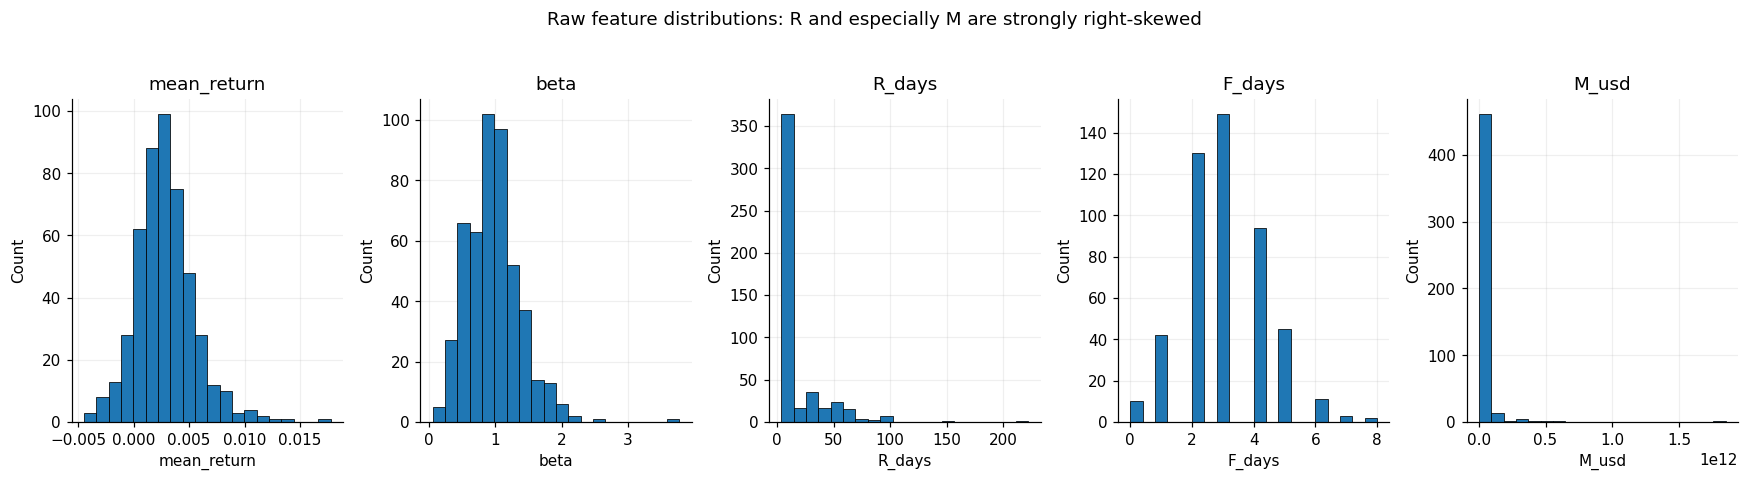

Skew of M: 11.68 raw -> 1.08 after log1p


In [61]:
# Task 2.1: visualise the original feature distributions before scaling.
# These plots use the same five raw features that are later used to build
# the risk-and-return and RFM clustering matrices.

# Keep the feature order consistent with the coursework's RFM discussion.
plot_features = [
    ("MeanWeeklyReturn", "mean_return"),
    ("WeeklyBeta", "beta"),
    ("R", "R_days"),
    ("F", "F_days"),
    ("M", "M_usd"),
]

# Create one histogram for each original feature, using a common figure row.
fig, axes = plt.subplots(1, 5, figsize=(16, 4.2))

for ax, (column, label) in zip(axes, plot_features):
    # Ignore missing and infinite values for plotting only; do not alter data.
    values = pd.to_numeric(features[column], errors="coerce")
    values = values.replace([np.inf, -np.inf], np.nan).dropna()

    ax.hist(values, bins=20, edgecolor="black", linewidth=0.5)
    ax.set_xlabel(label)
    ax.set_ylabel("Count")
    ax.set_title(label)

# Give the whole figure a clear heading and prevent axis labels overlapping.
fig.suptitle(
    "Raw feature distributions: R and especially M are strongly right-skewed",
    y=1.03
)
fig.tight_layout()
plt.show()
plt.close(fig)

# Report how much the log1p transformation reduces Monetary skewness.
# The LogM column is created in the following cell; calculate it here only
# for this diagnostic so the existing feature-preparation cell remains intact.
raw_m_skew = features["M"].skew()
log_m_skew = np.log1p(features["M"]).skew()
print(
    f"Skew of M: {raw_m_skew:.2f} raw -> "
    f"{log_m_skew:.2f} after log1p"
)

# Interpretation guide: compare the histogram shapes and the two skew values.
# A smaller absolute skew after log1p indicates that the transformation
# has reduced the right tail; it does not remove every outlier.

In [62]:
# Code for the current analysis step.
features['LogM'] = np.log1p(features['M'])
columns = metrics + ['LogM']
q1 = features[columns].quantile(0.25)
q3 = features[columns].quantile(0.75)
iqr = q3 - q1
outliers = features[columns].lt(q1 - 1.5 * iqr) | features[columns].gt(q3 + 1.5 * iqr)
display(pd.DataFrame({'Skew': features[columns].skew(), 'IQR outliers': outliers.sum()}))
matrices = {}
for kind, cols in {'risk': ['MeanWeeklyReturn', 'WeeklyBeta'],
                   'rfm': ['R', 'F', 'LogM']}.items():
    matrices[kind] = pd.DataFrame(StandardScaler().fit_transform(features[cols]),
                                  columns=cols, index=features['Ticker'])
    display(matrices[kind])

def model_matrix(df, kind):
    matrix = matrices[kind]
    return matrix.to_numpy(), list(matrix.columns)

def show_chart(fig):
    fig.tight_layout()
    plt.show()
    plt.close(fig)

,Skew,IQR outliers
MeanWeeklyReturn,0.867516,15
WeeklyBeta,1.103650,10
R,3.645784,115
F,0.424735,2
M,11.683797,45
LogM,1.079057,13


,MeanWeeklyReturn,WeeklyBeta
Ticker,,
MMM,-0.647333,-0.257093
AOS,-0.327124,0.169834
ABT,-0.711939,-0.958794
ABBV,0.336742,-1.347513
ACN,-0.181507,0.416802
...,...,...
XYL,-0.566038,0.404710
YUM,-0.396356,-0.841101
ZBRA,-0.632752,1.584399


,R,F,LogM
Ticker,,,
MMM,-0.441238,0.759941,0.317572
AOS,-0.441238,-0.744463,-1.488397
ABT,-0.441238,-1.496666,0.640699
ABBV,-0.441238,0.007739,1.345132
ACN,-0.441238,-0.744463,1.054229
...,...,...,...
XYL,0.731344,0.007739,-0.678630
YUM,1.669409,-1.496666,-0.386709
ZBRA,-0.441238,0.759941,-0.891771


### 2.2 Agglomerative clustering

Ward linkage minimises increases in within-cluster variance using Euclidean distance on standardised inputs. The dendrogram shows hierarchical structure, but early merges cannot be reversed and outliers can affect the result. Candidate solutions with at least two shares per cluster are preferred, the highest silhouette score among eligible candidates is selected.

In [63]:
# Define the clustering routine used to evaluate Ward and K-Means solutions.
def run_clustering(df, method):
    records = []
    labels = {}
    profiles = []
    sizes = []
    candidate_profiles = []
    for kind in ['risk', 'rfm']:
        X, cols = model_matrix(df, kind)
        if method == 'Ward':
            Z = linkage(X, method='ward', metric='euclidean')
        candidates = []
        for k in range(2, min(8, len(df) - 1) + 1):
            if method == 'Ward':
                fit = AgglomerativeClustering(n_clusters=k, linkage='ward')
                y = fit.fit_predict(X)
                inertia = np.nan
            else:
                fit = KMeans(n_clusters=k, random_state=SEED, n_init=30)
                y = fit.fit_predict(X)
                inertia = float(fit.inertia_)
            counts = pd.Series(y).value_counts().sort_index()
            s = silhouette_score(X, y) if 1 < len(counts) < len(df) else np.nan
            if len(counts) != k or not np.isfinite(s):
                continue
            for lab in counts.index:
                group = df.loc[y == lab]
                candidate_profiles.append(dict(FeatureSet=kind, Method=method, K=k, Cluster=int(lab), Size=len(group), **group[['MeanWeeklyReturn', 'WeeklyBeta', 'R', 'F', 'M']].mean().to_dict()))
            candidates.append(dict(FeatureSet=kind, Method=method, K=k, Silhouette=float(s), Inertia=inertia, MinClusterSize=int(counts.min()), MaxClusterSize=int(counts.max())))
            for lab, number in counts.items():
                sizes.append(dict(FeatureSet=kind, Method=method, K=k, Cluster=int(lab), Size=int(number)))
        if not candidates:
            raise ValueError(f'No feasible cluster counts for {kind} {method}')
        records.extend(candidates)
        qualified = [c for c in candidates if c['MinClusterSize'] >= 2]
        best = max(qualified or candidates, key=lambda c: (c['Silhouette'], -c['K']))
        for candidate in candidates:
            candidate['Selected'] = candidate['K'] == best['K']
        k = best['K']
        if method == 'Ward':
            y = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X)
        else:
            y = KMeans(n_clusters=k, random_state=SEED, n_init=30).fit_predict(X)
        key = f'{kind}_{method.lower()}'
        labels[key] = y
        df[key] = y
        for cluster, group in df.groupby(key):
            row = {'FeatureSet': kind, 'Method': method, 'Cluster': int(cluster), 'Size': len(group)}
            for v in ['MeanWeeklyReturn', 'WeeklyBeta', 'R', 'F', 'M']:
                row[v] = group[v].mean()
            profiles.append(row)
    return df, pd.DataFrame(records), pd.DataFrame(profiles), pd.DataFrame(sizes), labels, pd.DataFrame(candidate_profiles)

In [64]:
# Run Ward hierarchical clustering for both feature sets and review diagnostics.
features, ward_diagnostics, ward_profiles, ward_sizes, ward_labels, ward_candidates = run_clustering(features, 'Ward')
display(ward_diagnostics.drop(columns='Inertia').round(4))
display(ward_candidates.round(4))

,FeatureSet,Method,K,Silhouette,MinClusterSize,MaxClusterSize,Selected
0,risk,Ward,2,0.3395,92,394,True
1,risk,Ward,3,0.2738,92,230,False
2,risk,Ward,4,0.2821,48,182,False
3,risk,Ward,5,0.3041,48,182,False
4,risk,Ward,6,0.3204,5,182,False
5,risk,Ward,7,0.3240,5,160,False
6,risk,Ward,8,0.3208,5,160,False
7,rfm,Ward,2,0.3680,82,404,True
8,rfm,Ward,3,0.3040,82,250,False
9,rfm,Ward,4,0.2888,43,207,False


,FeatureSet,Method,K,Cluster,Size,MeanWeeklyReturn,WeeklyBeta,R,F,M
0,risk,Ward,2,0,394,0.0020,0.8979,19.6447,2.9416,3.020963e+10
1,risk,Ward,2,1,92,0.0063,1.2981,23.6739,3.1957,7.878092e+10
2,risk,Ward,3,0,230,0.0015,1.1096,18.9304,3.0565,3.380100e+10
3,risk,Ward,3,1,92,0.0063,1.2981,23.6739,3.1957,7.878092e+10
4,risk,Ward,3,2,164,0.0029,0.6012,20.6463,2.7805,2.517294e+10
...,...,...,...,...,...,...,...,...,...,...
65,rfm,Ward,8,3,43,0.0028,1.0081,16.8372,5.3721,1.496218e+10
66,rfm,Ward,8,4,141,0.0025,0.9223,11.1702,3.4468,1.121211e+10
67,rfm,Ward,8,5,18,0.0053,1.3512,17.5000,4.5556,3.504407e+11
68,rfm,Ward,8,6,66,0.0025,0.9336,11.0758,1.8636,1.085987e+10


#### Required Ward dendrograms (last 30 merges)

The two panels below show the Ward hierarchies for the risk-and-return matrix and the RFM matrix. Each panel displays the final 30 merges and marks the selected cluster cut with a dashed horizontal line.

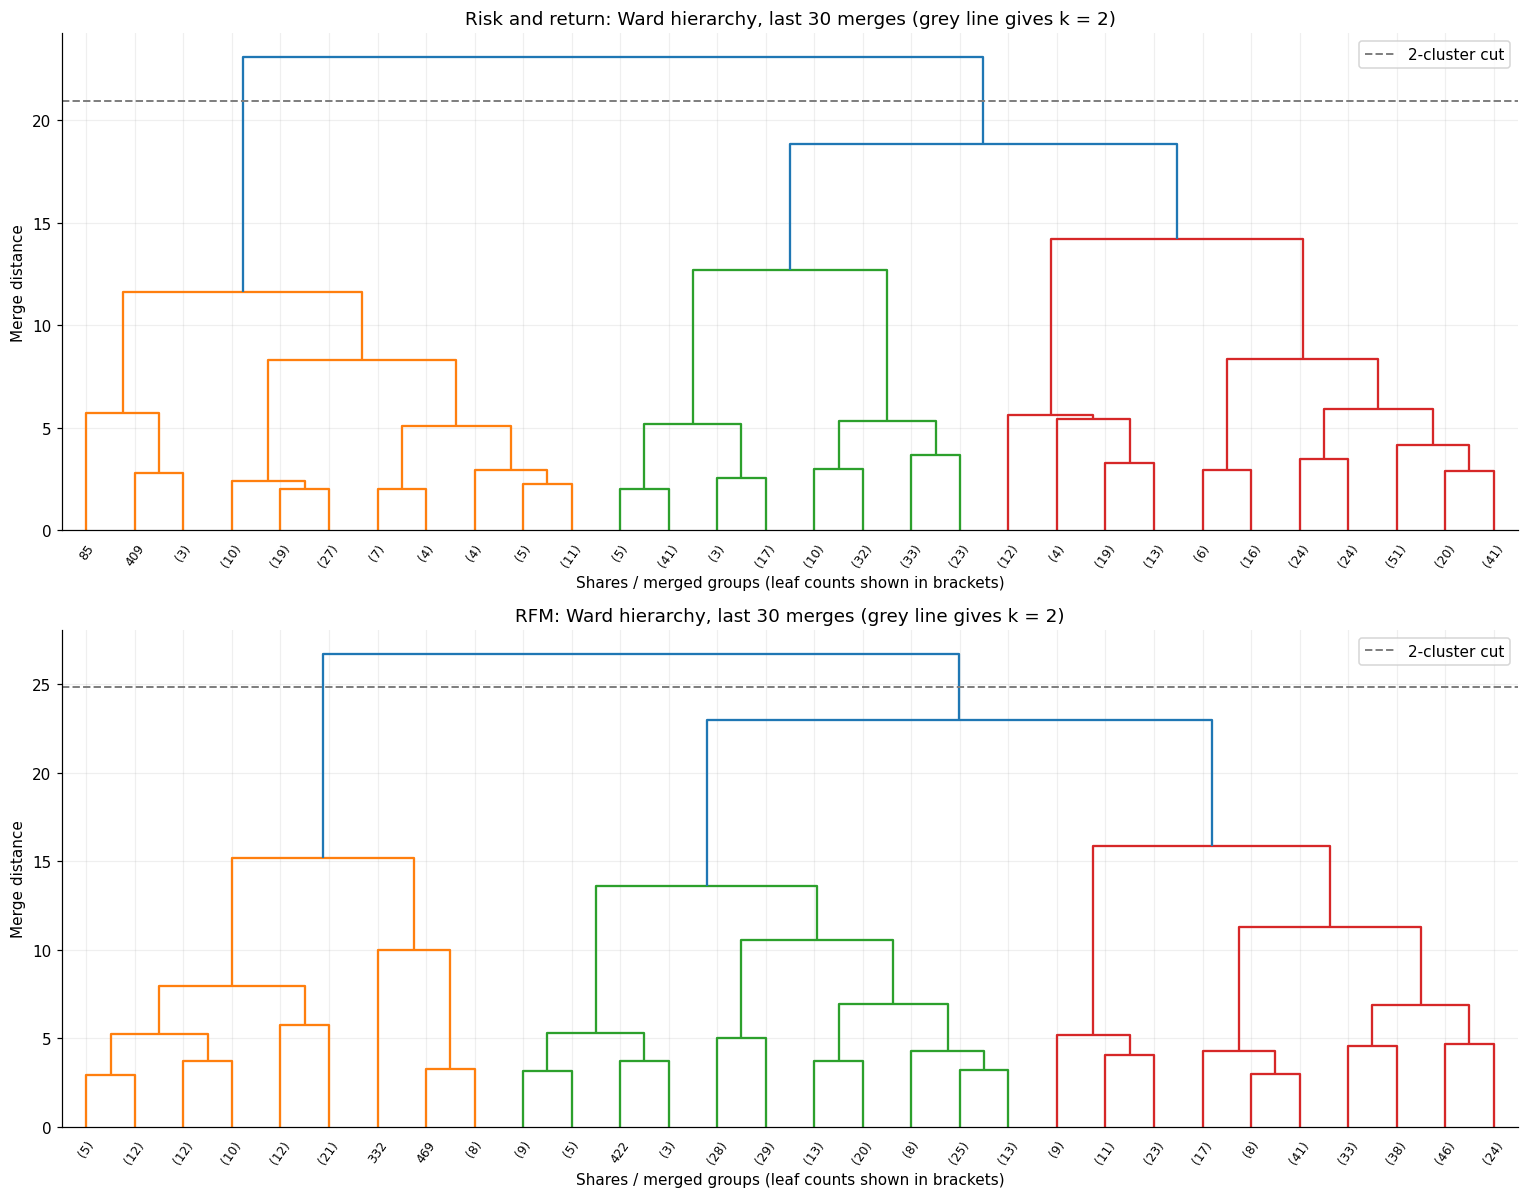

In [65]:
# Draw the required Ward dendrograms for risk-and-return and RFM, with selected cuts.
# Task 2.2: two labelled, truncated Ward dendrograms with selected-k cut lines.
from scipy.cluster.hierarchy import linkage, dendrogram

fig, axes = plt.subplots(2, 1, figsize=(14, 11))
for ax, feature_set, title in zip(
    axes,
    ["risk", "rfm"],
    ["Risk and return", "RFM"]
):
    X, cols = model_matrix(features, feature_set)
    Z = linkage(X, method="ward", metric="euclidean")

    # Use the k selected by the Ward silhouette comparison for this matrix.
    selected_row = ward_diagnostics[
        (ward_diagnostics["FeatureSet"] == feature_set) &
        (ward_diagnostics["Selected"])
    ].iloc[0]
    selected_k = int(selected_row["K"])

    # Height between the (n-k)th and next Ward merge gives a k-cluster cut.
    n_obs = X.shape[0]
    lower = Z[n_obs - selected_k - 1, 2] if n_obs - selected_k - 1 >= 0 else 0.0
    upper = Z[n_obs - selected_k, 2] if n_obs - selected_k < len(Z) else Z[-1, 2]
    cut_height = (lower + upper) / 2.0

    dendrogram(
        Z,
        truncate_mode="lastp",
        p=30,
        show_leaf_counts=True,
        leaf_rotation=55,
        leaf_font_size=8,
        ax=ax
    )
    ax.axhline(
        y=cut_height,
        color="grey",
        linestyle="--",
        linewidth=1.3,
        label=f"{selected_k}-cluster cut"
    )
    ax.set_title(f"{title}: Ward hierarchy, last 30 merges (grey line gives k = {selected_k})")
    ax.set_xlabel("Shares / merged groups (leaf counts shown in brackets)")
    ax.set_ylabel("Merge distance")
    ax.legend(loc="upper right")

fig.tight_layout()
show_chart(fig)
fig.savefig(OUT / "task2_2_ward_dendrograms.png", dpi=180, bbox_inches="tight")

### 2.3 K means clustering

K means minimises within-cluster squared distances and is sensitive to initialisation, outliers and non-spherical cluster shapes. A fixed seed and 30 initialisations are used for each candidate. Silhouette, inertia and cluster sizes are compared; the same selection rule is applied.

,FeatureSet,Method,K,Silhouette,Inertia,MinClusterSize,MaxClusterSize,Selected
0,risk,KMeans,2,0.3869,621.6344,143,343,True
1,risk,KMeans,3,0.3289,461.1787,119,202,False
2,risk,KMeans,4,0.3270,371.5771,40,160,False
3,risk,KMeans,5,0.3406,309.6131,27,166,False
4,risk,KMeans,6,0.3349,265.0971,5,156,False
5,risk,KMeans,7,0.3315,227.4762,5,143,False
6,risk,KMeans,8,0.3542,194.3617,5,136,False
7,rfm,KMeans,2,0.4231,1066.8319,68,418,True
8,rfm,KMeans,3,0.3250,796.6144,64,270,False
9,rfm,KMeans,4,0.3409,609.8325,61,212,False


,FeatureSet,Method,K,Cluster,Size
0,risk,KMeans,2,0,143
1,risk,KMeans,2,1,343
2,risk,KMeans,3,0,202
3,risk,KMeans,3,1,165
4,risk,KMeans,3,2,119
...,...,...,...,...,...
65,rfm,KMeans,8,3,66
66,rfm,KMeans,8,4,1
67,rfm,KMeans,8,5,11
68,rfm,KMeans,8,6,140


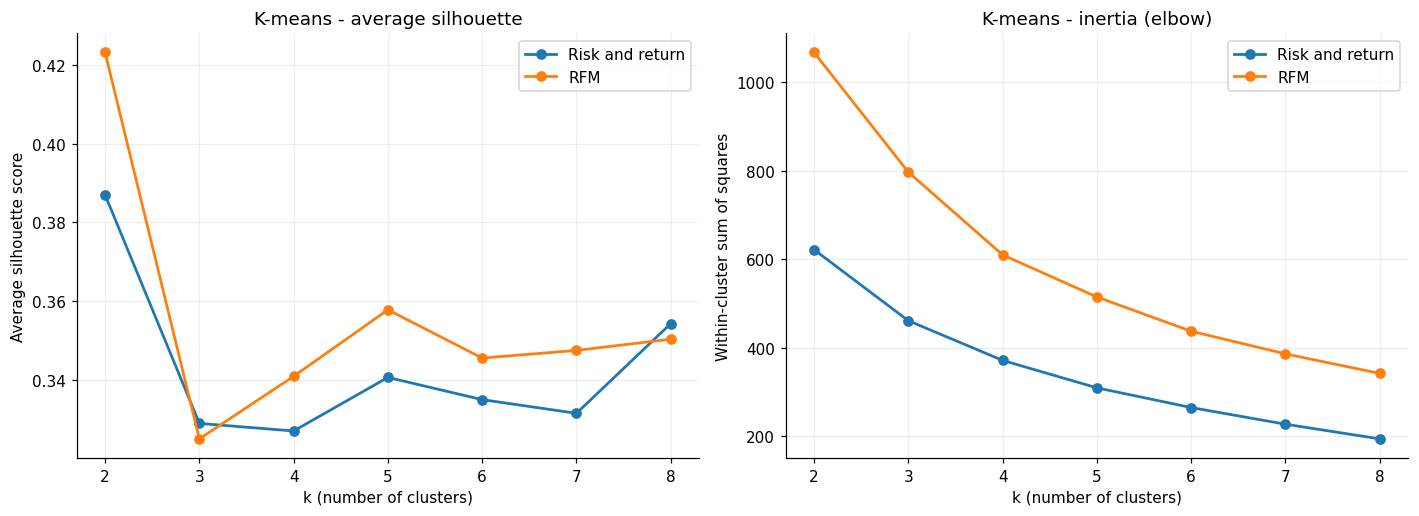

In [66]:
# Run K-Means for both feature sets and plot silhouette scores and inertia.
features, km_diagnostics, km_profiles, km_sizes, km_labels, km_candidates = run_clustering(features, 'KMeans')
display(km_diagnostics.round(4))
display(km_sizes)
diagnostics = pd.concat([ward_diagnostics, km_diagnostics], ignore_index=True)
profiles = pd.concat([ward_profiles, km_profiles], ignore_index=True)

# Task 2.3: K-Means average silhouette and inertia (elbow) plots.
# The two feature sets are compared on the same axes, as required in the example.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

for feature_set, label in [("risk", "Risk and return"), ("rfm", "RFM")]:
    subset = km_diagnostics[
        km_diagnostics["FeatureSet"] == feature_set
    ].sort_values("K")
    axes[0].plot(
        subset["K"], subset["Silhouette"],
        marker="o", linewidth=1.8, label=label
    )
    axes[1].plot(
        subset["K"], subset["Inertia"],
        marker="o", linewidth=1.8, label=label
    )

axes[0].set_title("K-means - average silhouette")
axes[0].set_xlabel("k (number of clusters)")
axes[0].set_ylabel("Average silhouette score")
axes[0].set_xticks(range(2, 9))
axes[0].legend()

axes[1].set_title("K-means - inertia (elbow)")
axes[1].set_xlabel("k (number of clusters)")
axes[1].set_ylabel("Within-cluster sum of squares")
axes[1].set_xticks(range(2, 9))
axes[1].legend()

fig.tight_layout()
show_chart(fig)
fig.savefig(OUT / "task2_3_kmeans_silhouette_inertia.png", dpi=180, bbox_inches="tight")


### 2.4 Cluster profiles and algorithm comparison

Profiles use original units. For RFM, PCA projects the standardised three-dimensional features into two dimensions for display only, clustering uses all three features. The axis labels report variance explained.

,FeatureSet,Method,Cluster,Size,MeanWeeklyReturn,WeeklyBeta,R,F,M
0,risk,Ward,0,394,0.0020,0.8979,19.6447,2.9416,3.020963e+10
1,risk,Ward,1,92,0.0063,1.2981,23.6739,3.1957,7.878092e+10
2,rfm,Ward,0,404,0.0029,0.9666,12.7153,3.1708,3.783020e+10
3,rfm,Ward,1,82,0.0029,1.0089,58.3049,2.0976,4.715898e+10
4,risk,KMeans,0,143,0.0053,1.3505,22.6364,3.1469,8.143839e+10
5,risk,KMeans,1,343,0.0018,0.8166,19.4781,2.9242,2.187973e+10
6,rfm,KMeans,0,418,0.0028,0.9723,13.4234,3.1866,3.269100e+10
7,rfm,KMeans,1,68,0.0030,0.9823,63.3382,1.7794,8.067057e+10


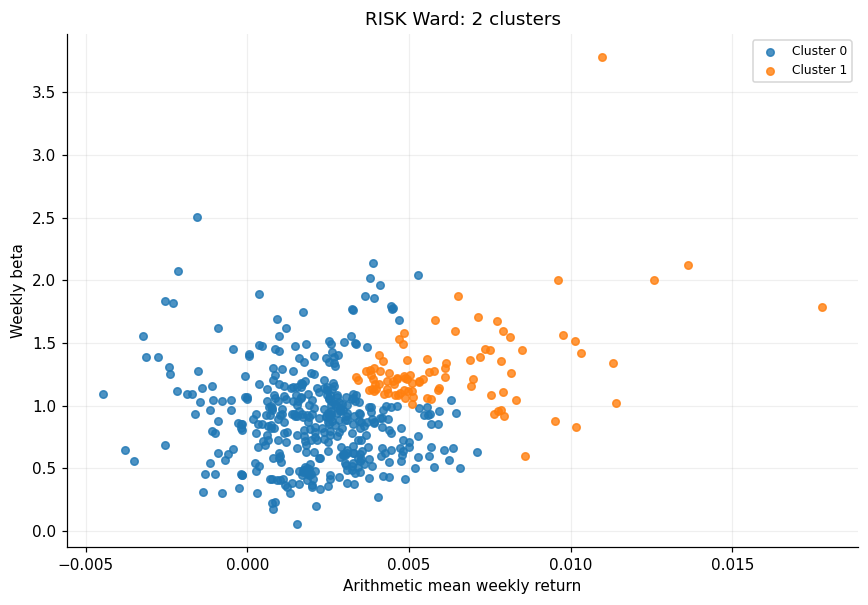

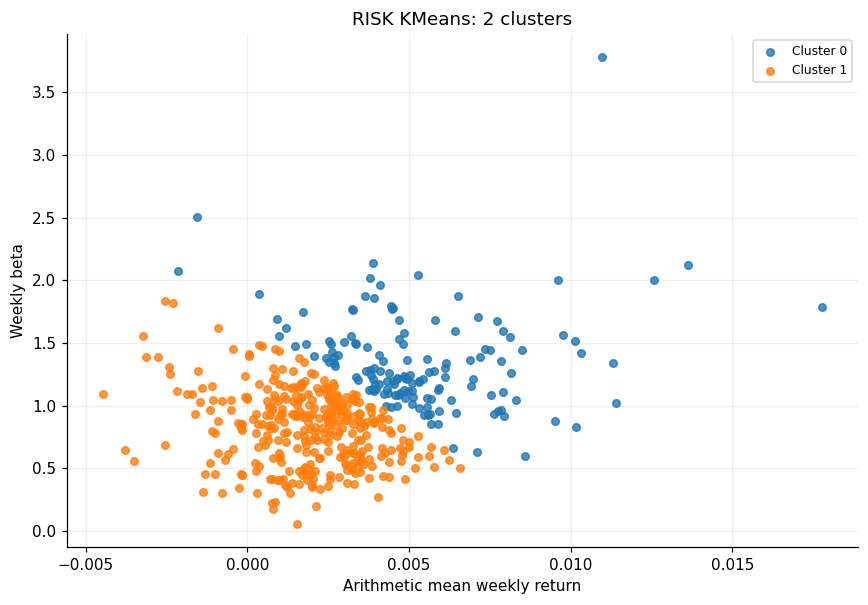

RISK algorithm agreement (ARI): 0.5976


risk_kmeans,0,1
risk_ward,,
0,51,343
1,92,0


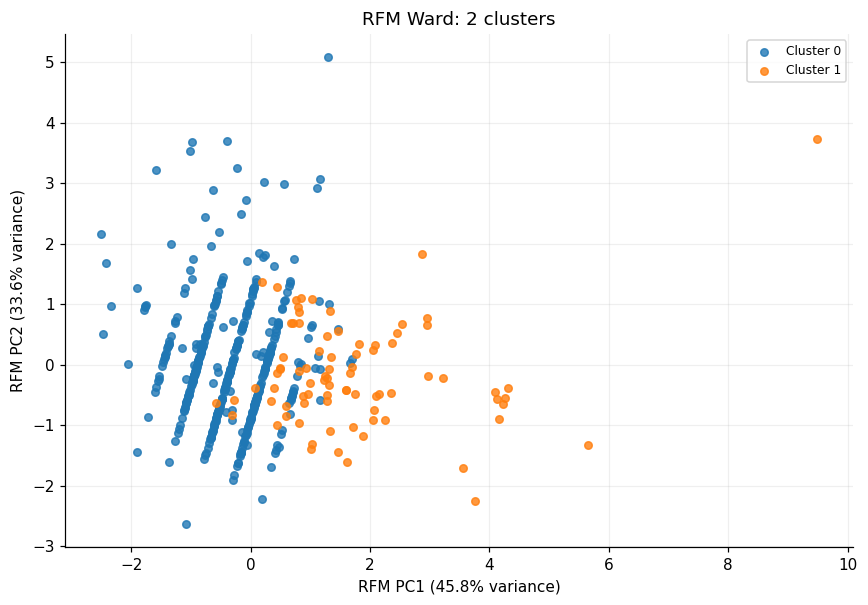

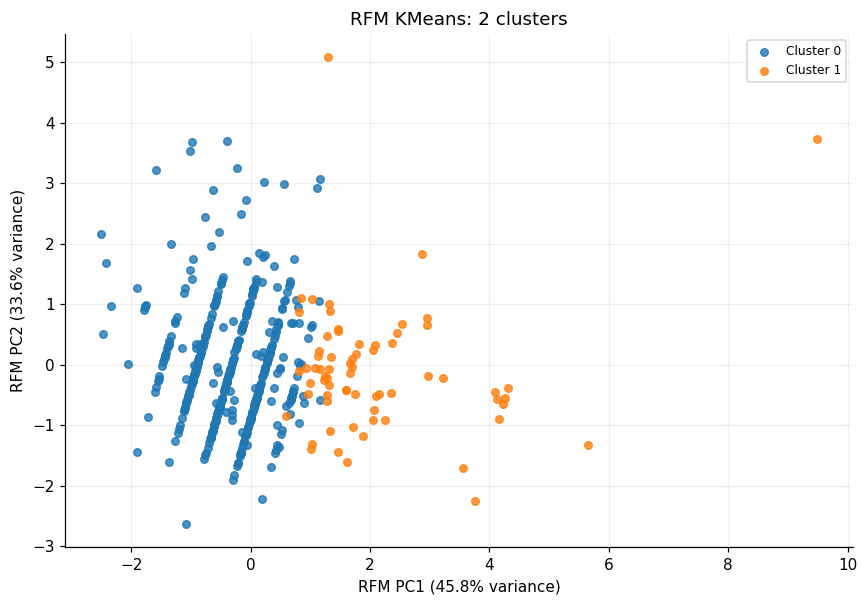

RFM algorithm agreement (ARI): 0.6998


rfm_kmeans,0,1
rfm_ward,,
0,396,8
1,22,60


In [67]:
# Compare cluster profiles in original units and create labelled cluster visualisations.
display(profiles.round(4))
for kind in ['risk', 'rfm']:
    X, cols = model_matrix(features, kind)
    for method in ['Ward', 'KMeans']:
        key = f'{kind}_{method.lower()}'
        df = features
        y = df[key].to_numpy()
        k = len(np.unique(y))
        fig, ax = plt.subplots(figsize=(8, 5.6))
        if kind == 'risk':
            a = df['MeanWeeklyReturn']
            b = df['WeeklyBeta']
            xlabel = 'Arithmetic mean weekly return'
            ylabel = 'Weekly beta'
        else:
            from sklearn.decomposition import PCA
            pca = PCA(n_components=2)
            proj = pca.fit_transform(X)
            a = proj[:, 0]
            b = proj[:, 1]
            xlabel = f'RFM PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)'
            ylabel = f'RFM PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)'
        for lab in sorted(set(y)):
            ii = y == lab
            ax.scatter(np.asarray(a)[ii], np.asarray(b)[ii], s=24, label=f'Cluster {lab}', alpha=0.8)
        ax.set(xlabel=xlabel, ylabel=ylabel, title=f'{kind.upper()} {method}: {k} clusters')
        ax.legend(fontsize=8)
        show_chart(fig)
    ward = features[f'{kind}_ward']
    kmeans = features[f'{kind}_kmeans']
    print(f'{kind.upper()} algorithm agreement (ARI): {adjusted_rand_score(ward, kmeans):.4f}')
    display(pd.crosstab(ward, kmeans))

### 2.5 RFM sensitivity and correlated inputs

#### 2.5.1 Correlation analysis

In [68]:
# Calculate RFM correlations and assess the effect of removing Monetary.
corr = features[['R', 'F', 'LogM']].corr()
display(corr.round(4))

,R,F,LogM
R,1.0000,-0.3463,0.1524
F,-0.3463,1.0000,0.0128
LogM,0.1524,0.0128,1.0000


Correlated variables can repeat information in Euclidean distances even after scaling. Correlation alone does not establish that a feature dominates a clustering solution.

#### 2.5.2 Removal of Monetary

In [69]:
# Compare Ward assignments with and without Monetary using the Adjusted Rand Index.
selected_k = features['rfm_ward'].nunique()
rf_matrix = StandardScaler().fit_transform(features[['R', 'F']])
features['rfm_ward_without_m'] = AgglomerativeClustering(n_clusters=selected_k, linkage='ward').fit_predict(rf_matrix)
ari = adjusted_rand_score(features['rfm_ward'], features['rfm_ward_without_m'])
print(f'Adjusted Rand index: {ari:.4f}')
for key in ['rfm_ward', 'rfm_ward_without_m']:
    print(key)
    display(features.groupby(key).agg(Count=('Ticker', 'size'), MeanM=('M', 'mean'),
                                      MedianM=('M', 'median'), MeanR=('R', 'mean'), MeanF=('F', 'mean')))
features.to_csv(OUT / 'feature_table_with_clusters.csv', index=False)
display(features[['Ticker', *metrics, 'risk_ward', 'risk_kmeans', 'rfm_ward', 'rfm_kmeans', 'rfm_ward_without_m']])

Adjusted Rand index: 0.8735
rfm_ward


,Count,MeanM,MedianM,MeanR,MeanF
rfm_ward,,,,,
0,404,3.783020e+10,1.604728e+10,12.715347,3.170792
1,82,4.715898e+10,1.784903e+10,58.304878,2.097561


rfm_ward_without_m


,Count,MeanM,MedianM,MeanR,MeanF
rfm_ward_without_m,,,,,
0,397,3.780680e+10,1.546400e+10,12.302267,3.209068
1,89,4.652963e+10,2.084781e+10,56.561798,2.011236


,Ticker,MeanWeeklyReturn,WeeklyBeta,R,F,M,risk_ward,risk_kmeans,rfm_ward,rfm_kmeans,rfm_ward_without_m
0,MMM,0.001142,0.869079,11,4,2.599146e+10,0,1,0,0,0
1,AOS,0.001991,1.042804,11,2,4.748980e+09,0,1,0,0,0
2,ABT,0.000971,0.583543,11,1,3.523027e+10,0,1,0,0,0
3,ABBV,0.003749,0.425366,11,3,6.837054e+10,0,1,0,0,0
4,ACN,0.002376,1.143300,11,2,5.199430e+10,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
481,XYL,0.001358,1.138380,36,3,1.017679e+10,0,1,1,0,1
482,YUM,0.001807,0.631435,56,1,1.339492e+10,0,1,1,1,1
483,ZBRA,0.001181,1.618418,11,4,8.326927e+09,0,0,0,0,0
484,ZBH,-0.001105,0.798203,11,2,9.609458e+09,0,1,0,0,0


## Task 3: Business Intelligence and Critical Review

### 3.2 Review of results and visualisation

#### 3.2.1 Cluster profiles and sector composition

risk_ward,0,1
Sector,,
Communication Services,15,5
Consumer Discretionary,36,11
Consumer Staples,32,0
Energy,16,4
Financials,61,13
Health Care,56,2
Industrials,57,21
Information Technology,45,29
Materials,20,3


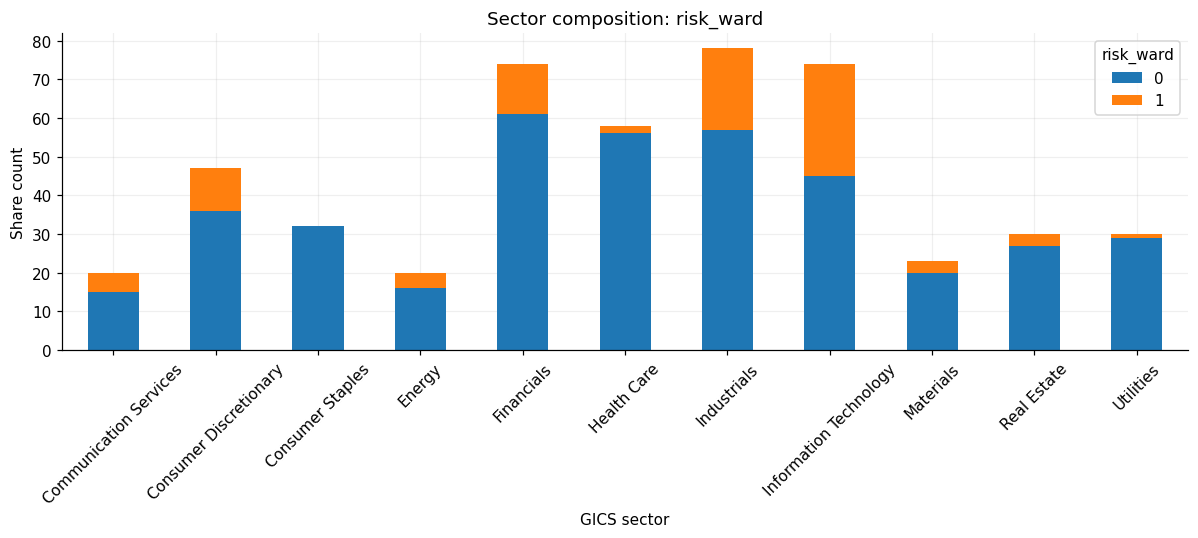

risk_kmeans,0,1
Sector,,
Communication Services,5,15
Consumer Discretionary,23,24
Consumer Staples,1,31
Energy,9,11
Financials,17,57
Health Care,2,56
Industrials,29,49
Information Technology,48,26
Materials,4,19


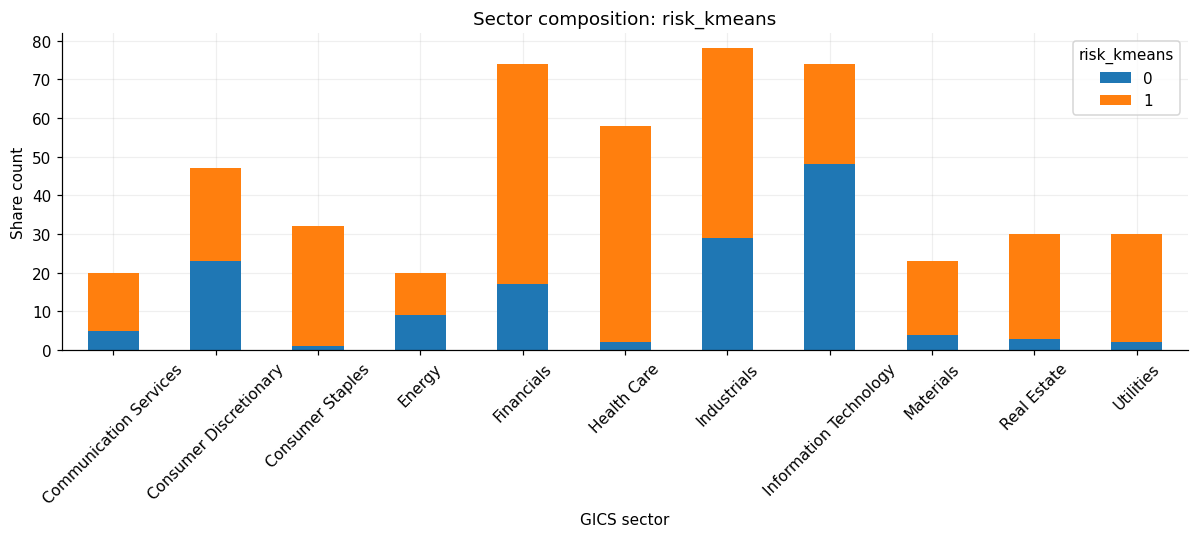

rfm_ward,0,1
Sector,,
Communication Services,16,4
Consumer Discretionary,38,9
Consumer Staples,25,7
Energy,18,2
Financials,64,10
Health Care,49,9
Industrials,72,6
Information Technology,56,18
Materials,15,8


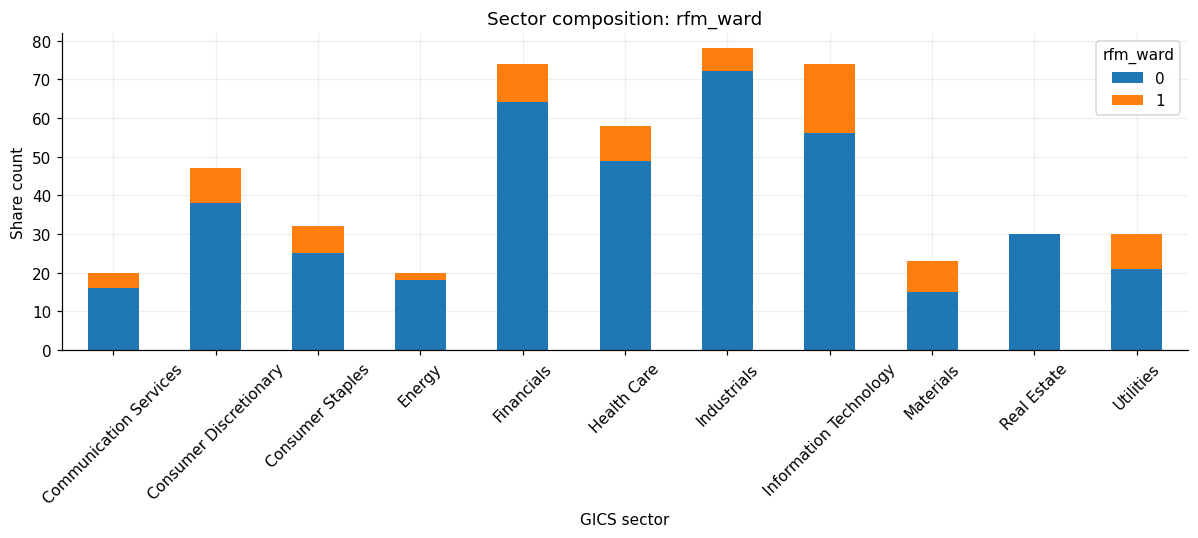

rfm_kmeans,0,1
Sector,,
Communication Services,18,2
Consumer Discretionary,39,8
Consumer Staples,27,5
Energy,19,1
Financials,64,10
Health Care,50,8
Industrials,73,5
Information Technology,60,14
Materials,17,6


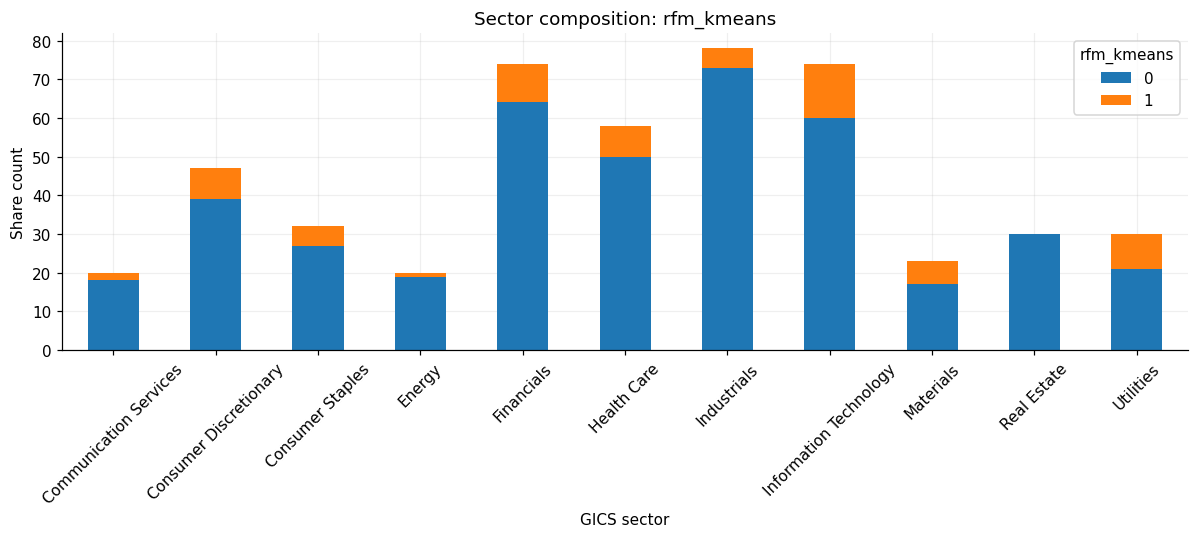

Sector percentages within each risk_ward cluster:


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
risk_ward,,,,,,,,,,,
0,3.8,9.1,8.1,4.1,15.5,14.2,14.5,11.4,5.1,6.9,7.4
1,5.4,12.0,0.0,4.3,14.1,2.2,22.8,31.5,3.3,3.3,1.1


Sector percentages within each risk_kmeans cluster:


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
risk_kmeans,,,,,,,,,,,
0,3.5,16.1,0.7,6.3,11.9,1.4,20.3,33.6,2.8,2.1,1.4
1,4.4,7.0,9.0,3.2,16.6,16.3,14.3,7.6,5.5,7.9,8.2


Sector percentages within each rfm_ward cluster:


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
rfm_ward,,,,,,,,,,,
0,4.0,9.4,6.2,4.5,15.8,12.1,17.8,13.9,3.7,7.4,5.2
1,4.9,11.0,8.5,2.4,12.2,11.0,7.3,22.0,9.8,0.0,11.0


Sector percentages within each rfm_kmeans cluster:


Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
rfm_kmeans,,,,,,,,,,,
0,4.3,9.3,6.5,4.5,15.3,12.0,17.5,14.4,4.1,7.2,5.0
1,2.9,11.8,7.4,1.5,14.7,11.8,7.4,20.6,8.8,0.0,13.2


In [70]:
# Review sector composition for each clustering solution and export sector summaries.
for key in ["risk_ward", "risk_kmeans", "rfm_ward", "rfm_kmeans"]:
    sector = pd.crosstab(features.Sector, features[key])
    display(sector)
    fig, ax = plt.subplots(figsize=(11, 5))
    sector.plot.bar(stacked=True, ax=ax, rot=45)
    ax.set(title=f"Sector composition: {key}", xlabel="GICS sector", ylabel="Share count")
    show_chart(fig)

# Sector composition as percentages within each cluster (easier cross-cluster comparison).
sector_outputs = {}
for key in ["risk_ward", "risk_kmeans", "rfm_ward", "rfm_kmeans"]:
    counts = pd.crosstab(features[key], features["Sector"])
    percentages = counts.div(counts.sum(axis=1), axis=0) * 100
    counts.to_csv(OUT / f"sector_counts_{key}.csv")
    percentages.to_csv(OUT / f"sector_percentages_{key}.csv")
    sector_outputs[key] = percentages
    print(f"Sector percentages within each {key} cluster:")
    display(percentages.round(1))

In [71]:
# Save final feature table, cluster assignments, diagnostics and profiles.
assignment_columns = [
    "Ticker", "Sector", "MeanWeeklyReturn", "WeeklyBeta", "R", "F", "M",
    "risk_ward", "risk_kmeans", "rfm_ward", "rfm_kmeans",
    "rfm_ward_without_m"
]
features[assignment_columns].to_csv(OUT / "final_feature_table_and_assignments.csv", index=False)
diagnostics.to_csv(OUT / "clustering_diagnostics.csv", index=False)
profiles.to_csv(OUT / "cluster_profiles_original_units.csv", index=False)
ward_sizes.to_csv(OUT / "ward_cluster_sizes.csv", index=False)
km_sizes.to_csv(OUT / "kmeans_cluster_sizes.csv", index=False)
corr.to_csv(OUT / "rfm_correlations.csv")
write_json(OUT / "sensitivity_results.json", {
    "selected_ward_rfm_k": int(selected_k),
    "monetary_removal_adjusted_rand_index": float(ari),
    "ward_vs_kmeans_risk_ari": float(adjusted_rand_score(features["risk_ward"], features["risk_kmeans"])),
    "ward_vs_kmeans_rfm_ari": float(adjusted_rand_score(features["rfm_ward"], features["rfm_kmeans"]))
})
provenance = json.loads((OUT / "provenance.json").read_text())
provenance.update({
    "observation_date": str(observation_date.date()),
    "valid_full_history_shares": int(len(histories)),
    "final_rfm_cluster_sample": int(len(features)),
    "week_labels": [str(week_labels.min().date()), str(week_labels.max().date())],
    "seed": SEED
})
write_json(OUT / "provenance.json", provenance)

print("Analysis completed. Outputs saved to:", OUT.resolve())
print("Final sample:", len(features), "shares")
print("Observation date:", observation_date.date())
print("Monetary-removal ARI:", round(float(ari), 4))

Analysis completed. Outputs saved to: /content/cwk1_analysis/outputs
Final sample: 486 shares
Observation date: 2024-12-31
Monetary-removal ARI: 0.8735


## Download coursework data and analysis outputs

Run the final cell after completing the analysis. It packages the raw data snapshots and all generated outputs into one ZIP file and automatically downloads it when running in Google Colab.

In [ ]:
# FINAL STEP: PACKAGE AND DOWNLOAD ALL COURSEWORK FILES
# This cell creates one ZIP file containing the downloaded market-data snapshots,
# the S&P 500 constituent list, validation logs, feature tables, cluster assignments,
# diagnostics, profiles, correlations and provenance information.
#
# Run this cell only after all previous analysis cells have completed successfully.

import zipfile
from pathlib import Path
from datetime import datetime, timezone

# Confirm that the expected analysis folders and final output table exist.
required_output = OUT / "final_feature_table_and_assignments.csv"
if not required_output.exists():
    raise FileNotFoundError(
        "The final feature table was not found. Run all notebook cells from top to bottom first."
    )

# Add a short README inside the analysis folder so the downloaded files are understandable.
readme_text = f"""
CWK1 - Market Analysis and Stock Segmentation Using RFM
========================================================

Study period: {START} inclusive to {END} exclusive
Benchmark: ^GSPC
Package created (UTC): {datetime.now(timezone.utc).isoformat()}

Folder guide
------------
data/
    S&P 500 constituent list and individual daily Yahoo Finance CSV snapshots.
outputs/
    Provenance, download failures, validation log, feature table, cluster assignments,
    clustering diagnostics, cluster profiles, cluster sizes, correlations, sensitivity
    results and sector composition tables.

Important
---------
The raw CSV files are preserved as downloaded/cached snapshots. The outputs are generated
by running the notebook from top to bottom. Include the notebook itself separately when
submitting the runnable code, and include your public GitHub repository address in the report.
"""
(ROOT / "README_downloaded_files.txt").write_text(readme_text.strip() + "\n", encoding="utf-8")

# Create the ZIP beside the analysis folder so it does not include itself.
zip_path = ROOT.parent / "CWK1_Data_and_Analysis_Outputs.zip"

# Package all files under cwk1_analysis, preserving the data/ and outputs/ folders.
with zipfile.ZipFile(zip_path, mode="w", compression=zipfile.ZIP_DEFLATED) as archive:
    for file_path in sorted(ROOT.rglob("*")):
        if file_path.is_file() and file_path.resolve() != zip_path.resolve():
            archive.write(file_path, arcname=file_path.relative_to(ROOT.parent))

print("Coursework package created:", zip_path)
print("Package size (MB):", round(zip_path.stat().st_size / (1024 * 1024), 2))

# In Google Colab, automatically start downloading the ZIP to your computer.
# If the notebook is running outside Colab, keep the ZIP at the path printed above.
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print("Google Colab was not detected.")
    print("Download the ZIP manually from the file path shown above.")
